<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [381]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [382]:
import random

In [383]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [384]:
len(l)

10000

In [385]:
l[:5]

[6, 9, 7, 5, 5]

In [386]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0301
3     0.0589
4     0.0846
5     0.1051
6     0.1334
7     0.1663
8     0.1441
9     0.1093
10    0.0829
11    0.0558
12    0.0295
Name: count, dtype: float64


<Axes: >

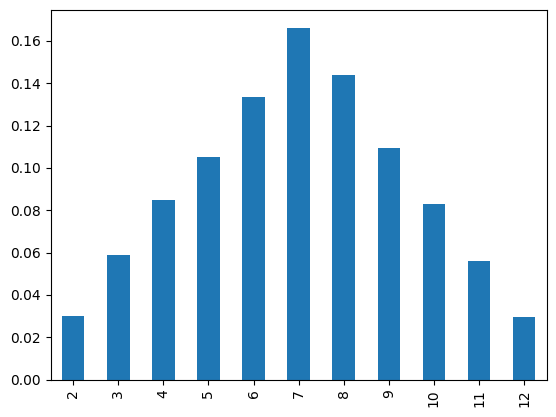

In [387]:
s.plot(kind='bar')

<Axes: >

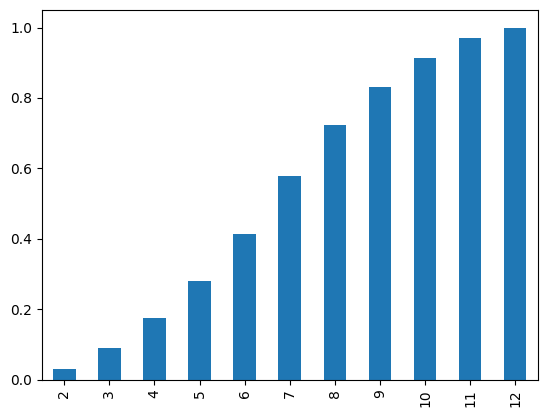

In [388]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [389]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[49.1483014  48.75491352 46.19080658 47.99473913 43.89761158 45.07859001
 47.21041508 54.87867727 44.25474968 53.16357775 60.47614988 47.9355491
 33.63608978 53.92422876 55.82728046 46.21854412 39.74209282 48.82086418
 38.14186304 43.3777696  50.36849667 52.28276484 50.5206459  42.61371871
 43.33681275 51.99094389 52.99186692 53.96332827 60.32069459 49.70896104
 56.17121234 49.03685045 53.62500481 52.63585959 57.76199043 57.46616473
 46.96235652 56.29969315 47.11337354 44.32105926 50.18936573 44.26415493
 60.20332857 47.23119718 49.19072299 62.75391569 46.97549669 52.47066926
 54.22188241 58.39329643 53.39683031 45.35693618 52.36044436 50.51386036
 40.83671037 48.75672096 48.12293887 51.47397506 48.88919955 50.00438896
 50.26989532 42.2895952  46.27644575 50.898949   51.42502788 36.80600587
 59.39991938 42.87352547 44.26735425 49.87291753 47.43299336 55.86847686
 46.8762103  50.94977603 53.77576016 51.47012186 53.85166325 47.77978209
 49.23651436 53.9674535  54.38950088 55.07857376 43.

In [390]:
sample.mean()

np.float64(49.659385167109114)

(array([  2.,  15.,  38., 148., 246., 269., 182.,  76.,  20.,   4.]),
 array([30.59191022, 34.27585946, 37.9598087 , 41.64375794, 45.32770718,
        49.01165642, 52.69560567, 56.37955491, 60.06350415, 63.74745339,
        67.43140263]),
 <BarContainer object of 10 artists>)

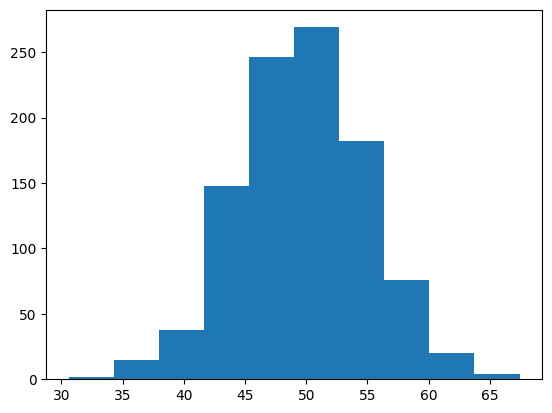

In [391]:
plt.hist(sample,bins=10)

In [392]:
sample_mean=sample.mean()
sample_std=sample.std()

In [393]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [394]:
sample.min()

np.float64(30.591910215095716)

In [395]:
sample.max()

np.float64(67.43140263182458)

In [396]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [397]:
probabilities=[dist.pdf(value) for value in values]

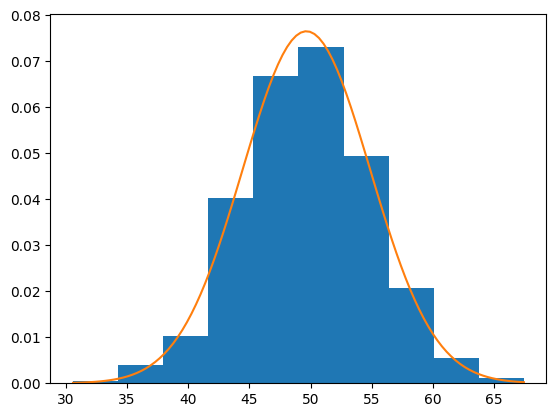

In [398]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_700/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

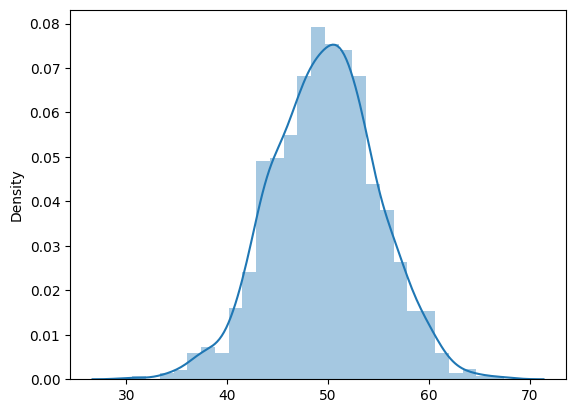

In [399]:
import seaborn as sns
sns.distplot(sample)

KDE

In [400]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [401]:
sample

array([27.40637087, 17.60994972, 20.34116708, 21.0391121 , 23.90577566,
       26.09854805, 19.3034138 , 20.48077372, 20.05448654, 12.19038813,
       14.86764233, 19.55118978, 24.55509569, 28.18771376, 20.43674955,
       18.89018274, 20.67417634, 14.99040693, 20.84699668, 21.07498754,
       18.26093704,  8.15703432, 18.29511606, 16.34591535, 25.87990903,
       24.84366416, 33.76989563, 23.30701736, 18.86960322, 17.40714562,
       23.38798471, 16.51019292, 21.47791597, 25.74555029, 28.15858923,
       23.89325725, 22.1426311 , 28.90342875, 15.29155521, 17.4518573 ,
       23.03806829, 19.3513768 ,  6.47697713, 17.06274108, 21.27296422,
       15.17810084, 26.25808346, 10.55998816, 15.66842781, 18.86257028,
       17.5923252 , 16.74037094, 17.6579964 , 19.88833871, 26.95650288,
       17.27461999, 17.58808655, 21.58617298, 20.48175924, 24.89534358,
       15.48523697,  9.68463865, 11.61849442, 26.16150719, 18.31805317,
       20.66819326, 19.57325484, 24.78369779, 20.36569963, 16.83

(array([ 2.,  0.,  2.,  5.,  6.,  5.,  6.,  8.,  8., 12., 16., 29., 32.,
        20., 31., 20., 15., 21., 18., 19.,  6.,  8., 10., 10., 11., 13.,
        19., 30., 28., 40., 45., 52., 65., 63., 61., 68., 47., 43., 34.,
        15., 17., 11., 11.,  6.,  3.,  2.,  4.,  1.,  1.,  1.]),
 array([ 5.59803041,  6.6333491 ,  7.66866779,  8.70398649,  9.73930518,
        10.77462387, 11.80994257, 12.84526126, 13.88057995, 14.91589864,
        15.95121734, 16.98653603, 18.02185472, 19.05717342, 20.09249211,
        21.1278108 , 22.1631295 , 23.19844819, 24.23376688, 25.26908557,
        26.30440427, 27.33972296, 28.37504165, 29.41036035, 30.44567904,
        31.48099773, 32.51631643, 33.55163512, 34.58695381, 35.62227251,
        36.6575912 , 37.69290989, 38.72822858, 39.76354728, 40.79886597,
        41.83418466, 42.86950336, 43.90482205, 44.94014074, 45.97545944,
        47.01077813, 48.04609682, 49.08141551, 50.11673421, 51.1520529 ,
        52.18737159, 53.22269029, 54.25800898, 55.29332767,

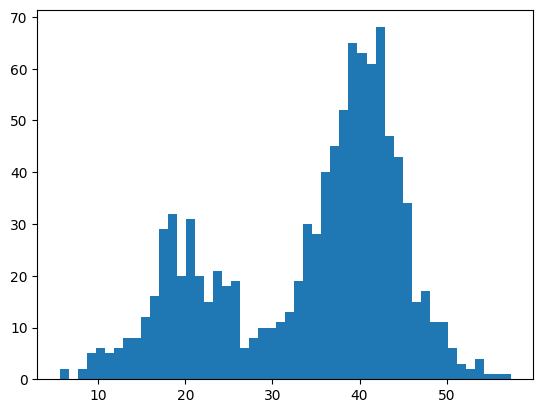

In [402]:
plt.hist(sample,bins=50)

In [403]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [404]:
dataset=sns.load_dataset("iris")

In [405]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

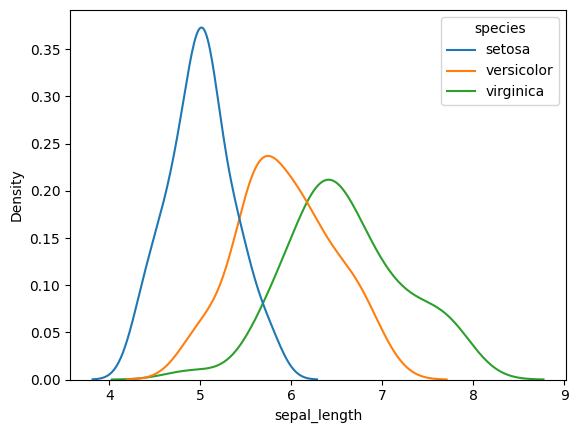

In [406]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

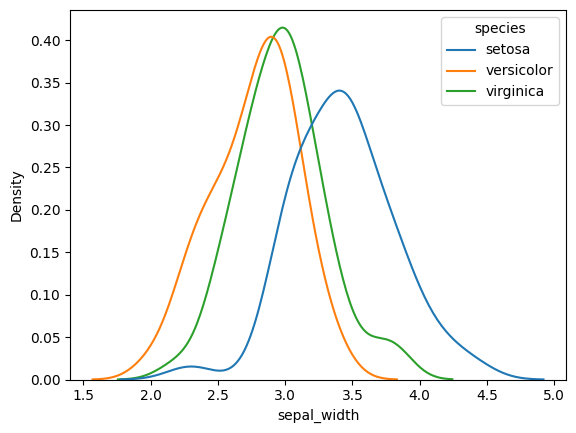

In [407]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

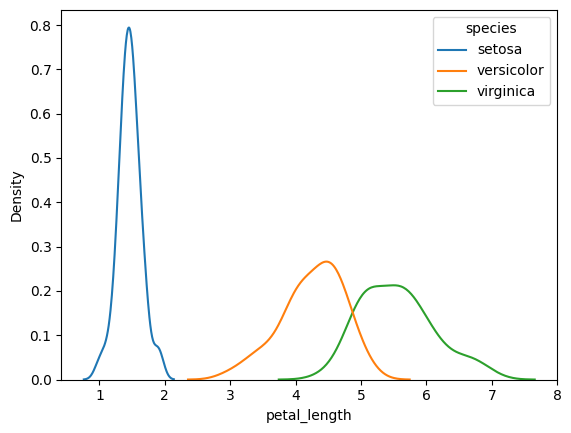

In [408]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

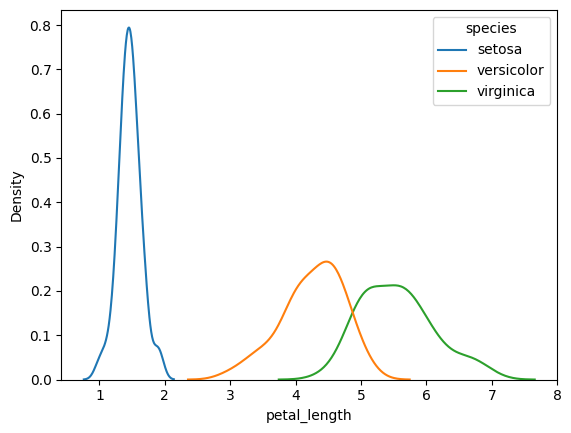

In [409]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [410]:
tips=sns.load_dataset("tips")

In [411]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

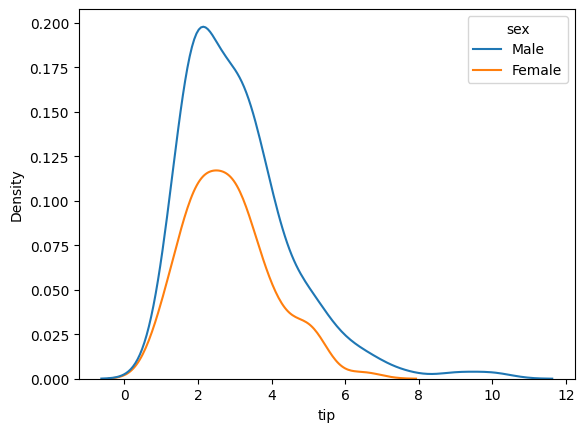

In [412]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

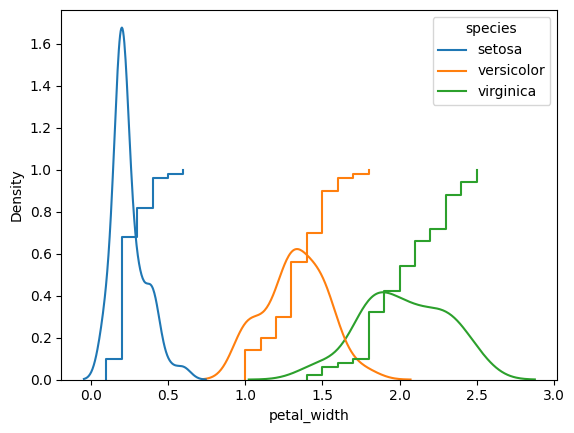

In [413]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [414]:
#contour plots

How to find distribution is normal or not?

In [415]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

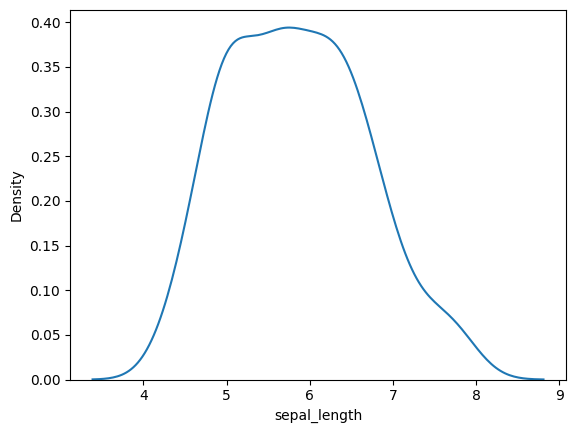

In [416]:
sns.kdeplot(iris["sepal_length"])

In [417]:
temp=sorted(iris['sepal_length'].tolist())

In [418]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [419]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [420]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

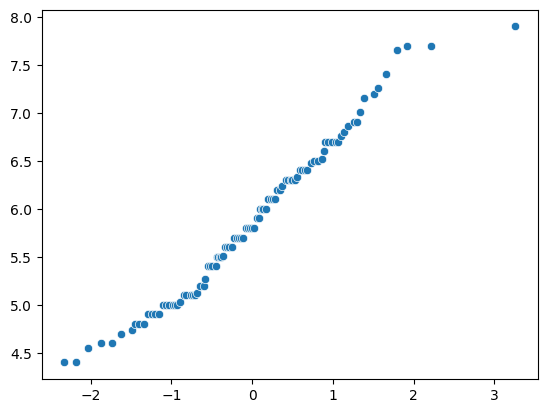

In [421]:
sns.scatterplot(x=x_quant,y=y_quant)

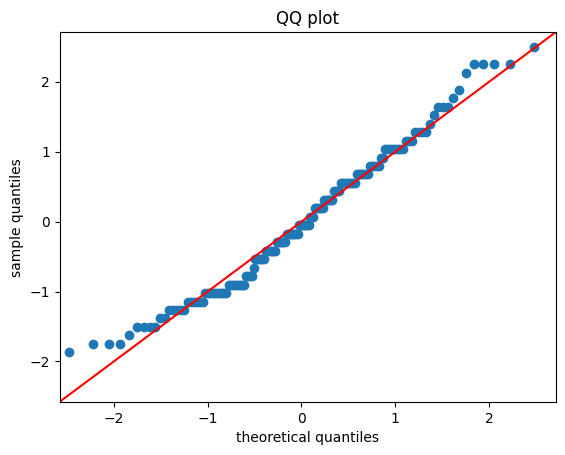

In [422]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [423]:
import scipy.stats as stats

In [424]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([104.,  99., 100.,  86., 118.,  94., 100.,  91., 120.,  88.]),
 array([6.16219427e-04, 1.00331122e-01, 2.00046026e-01, 2.99760929e-01,
        3.99475832e-01, 4.99190735e-01, 5.98905638e-01, 6.98620541e-01,
        7.98335444e-01, 8.98050347e-01, 9.97765250e-01]),
 <BarContainer object of 10 artists>)

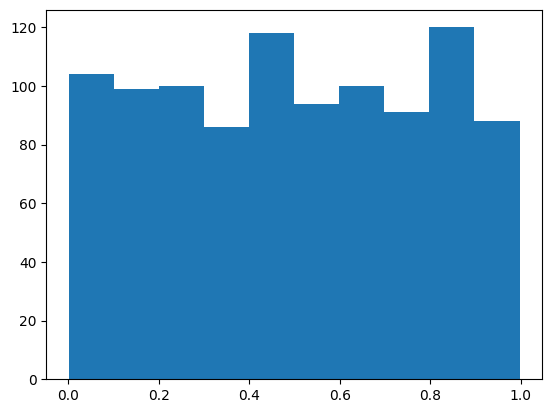

In [425]:
plt.hist(x)

PARETO DISTRIBUTION

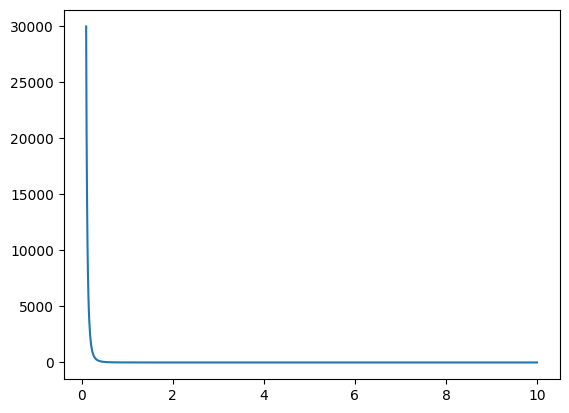

In [426]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

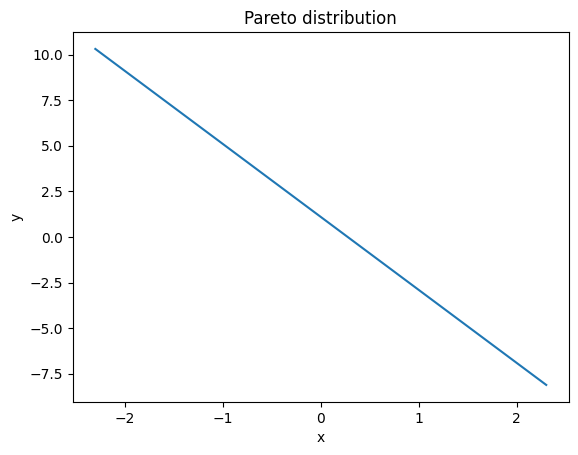

In [427]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [428]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([862.,  91.,  25.,   9.,   3.,   5.,   2.,   1.,   1.,   1.]),
 array([ 1.00029072,  2.60135266,  4.20241459,  5.80347653,  7.40453847,
         9.00560041, 10.60666235, 12.20772429, 13.80878623, 15.40984816,
        17.0109101 ]),
 <BarContainer object of 10 artists>)

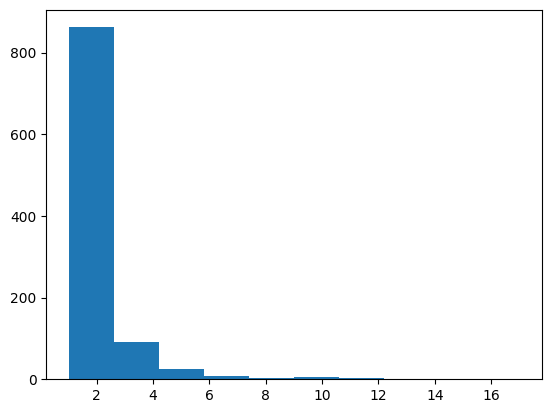

In [429]:
plt.hist(x)

In [430]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

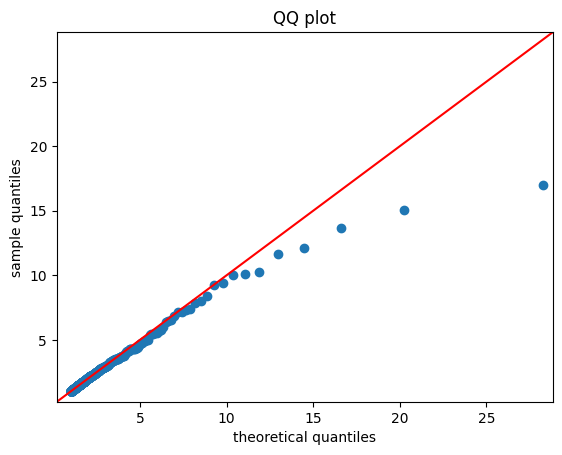

In [431]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [432]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [433]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [434]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [435]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [436]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [437]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_700/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

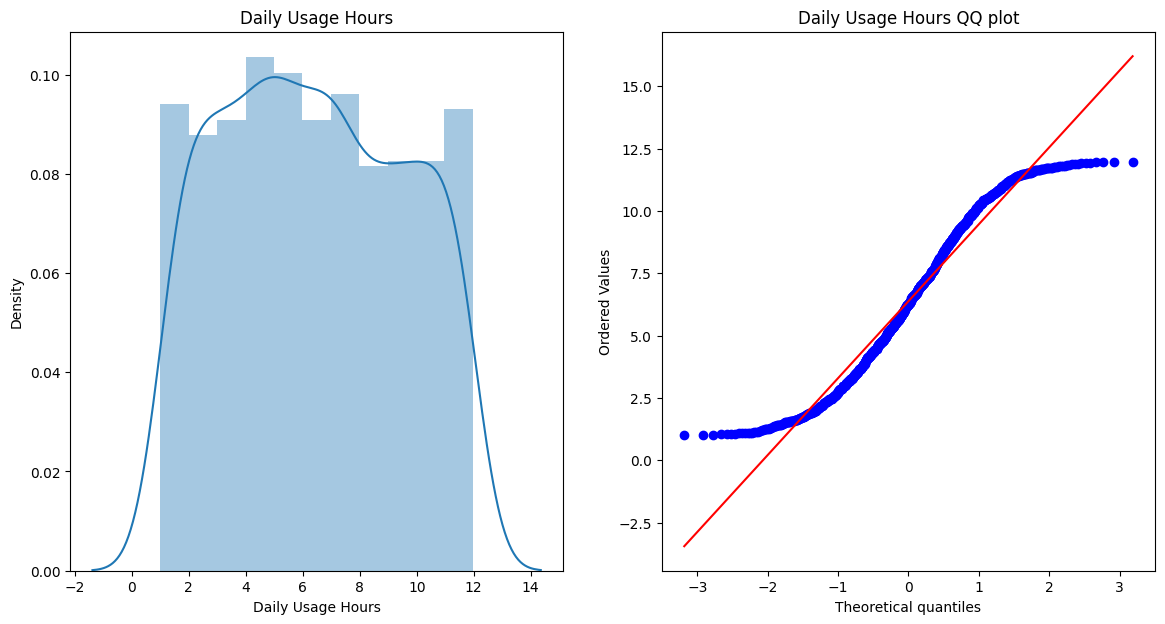

In [438]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

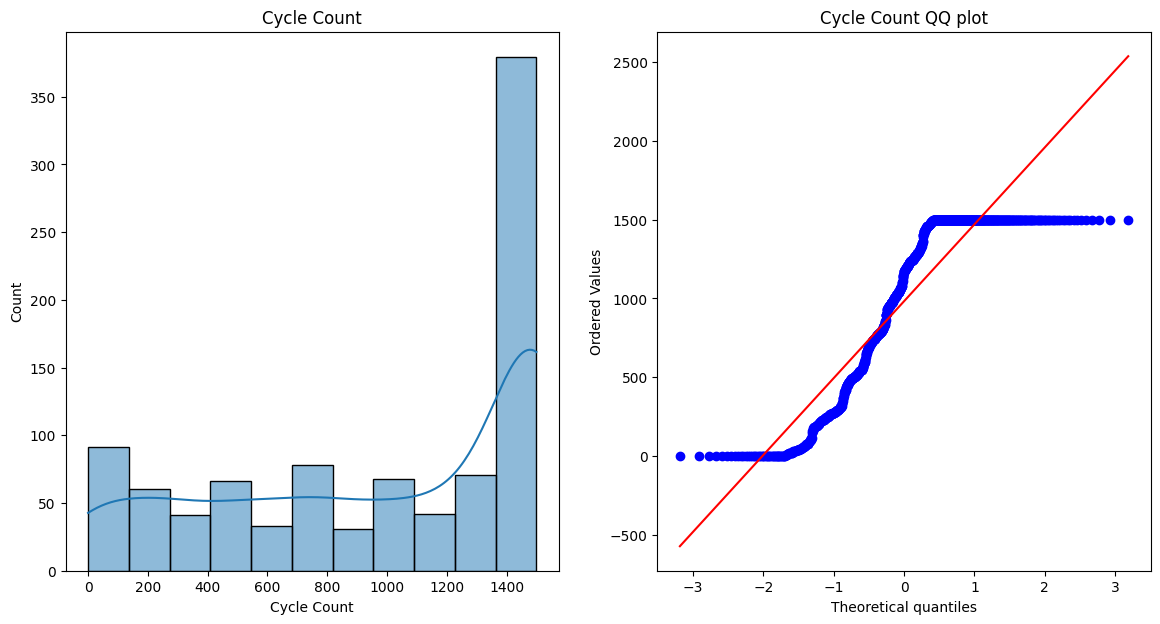

In [439]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [440]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [441]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [442]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [443]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [444]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.39166666666666666
Accuracy DT 0.6791666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [445]:
trf=FunctionTransformer(np.log1p)

In [446]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
1023           1.354568     0.000000        11.073878     7.313887
608            1.939296     0.000000        11.267766     6.541030
890            2.262692     0.000000        11.268469     5.384495
826            0.802495     0.693147        11.099136     6.622736
421            1.122015     0.000000        10.768780     5.690359
...                 ...          ...              ...          ...
1029           2.373431     0.000000        11.035019     7.313887
295            1.694168     0.000000        10.936013     7.313887
112            1.883123     0.693147        10.870719     3.496508
432            1.537473     0.000000        10.987172     7.313887
747            1.193224     0.000000        10.966110     7.313887

[960 rows x 4 columns]
      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
1133           1.676169     0.000000        11.062834     6.791221
695            2.141111     0.000000  

In [447]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5
Accuracy DT 0.6833333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[4 6 9 5 5 8 3 2 5 5 3 5 7 5 5 5 7 5 4 7 4 7 6 7 5 6 4 3 6 5 3 7 3 3 5 3 6
 6 1 6 4 5 3 6 9 8 2 3 3 7 4 5 6 4 5 6 3 5 5 5 6 6 4 7 4 4 4 9 4 5 7 6 5 5
 3 4 5 3 7 5 5 2 6 7 4 9 7 8 3 3 6 3 8 5 6 2 7 4 3 5 6 3 6 7 2 7 7 3 5 6 5
 4 6 6 4 3 3 6 5 3 5 4 4 5 4 4 4 6 3 2 7 6 4 4 4 5 2 4 2 4 3 4 6 8 6 3 5 6
 3 4 7 4 5 4 6 5 5 5 3 4 4 3 3 5 4 5 2 6 8 6 4 5 7 4 4 6 7 6 5 6 6 6 5 3 3
 6 6 4 5 6 5 8 9 3 7 4 5 4 5 4 4 5 6 4 2 3 7 4 4 5 3 4 6 3 5 6 5 2 4 4 1 5
 7 7 4 8 4 4 6 4 2 3 4 6 5 7 7 3 6 5 5 4 3 4 7 3 4 7 2 5 6 6 5 5 3 5 6 4 6
 2 6 6 4 6 4 5 5 6 1 8 7 6 5 4 5 5 6 3 3 7 6 4 2 7 7 6 6 4 7 4 5 2 6 6 6 8
 6 3 4 5 7 5 7 8 6 2 6 3 7 4 6 3 5 5 3 4 4 4 5 8 5 3 4 6 6 6 5 3 6 5 6 5 5
 8 3 5 6 2 5 5 7 6 5 8 5 4 2 4 7 6 5 5 4 6 5 7 5 5 3 8 3 4 5 6 5 6 4 5 4 5
 8 6 4 6 8 6 8 7 4 4 5 7 6 7 2 5 6 4 8 6 4 6 5 6 5 3 7 5 3 5 3 5 3 6 6 8 6
 4 7 4 4 6 3 4 5 6 4 7 6 3 2 3 6 4 3 4 5 4 5 4 4 6 6 4 3 5 4 7 4 4 7 6 4 5
 4 5 7 5 3 5 6 6 5 4 6 7 3 5 5 6 6 4 8 5 6 4 7 5 4 6 5 5 6 6 4 8 2 3 7 5 4
 3 3 4 6 5 4 5 4 5 6 6 5 

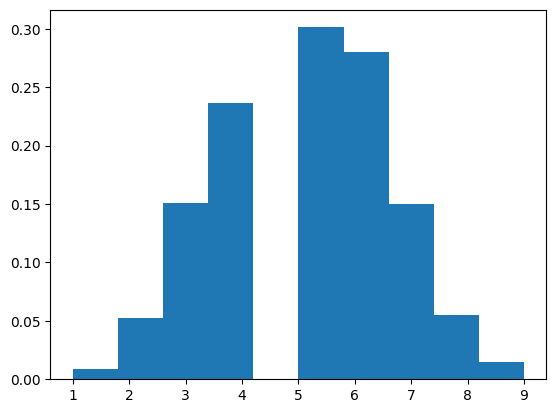

In [448]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [449]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [450]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.47338567, 0.49432806, 0.4931771 , ..., 0.50024076, 0.4988541 ,
       0.51747224])

In [451]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

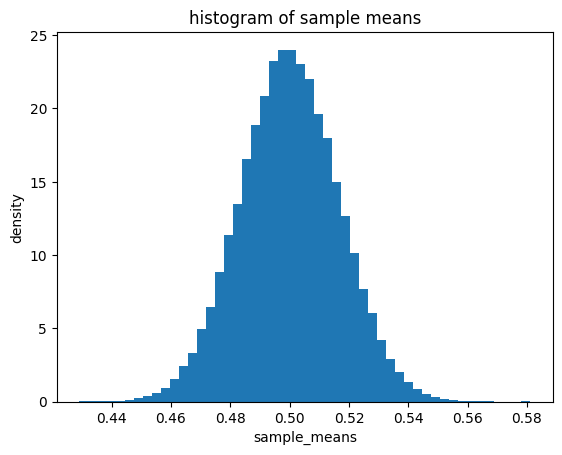

In [452]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [453]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

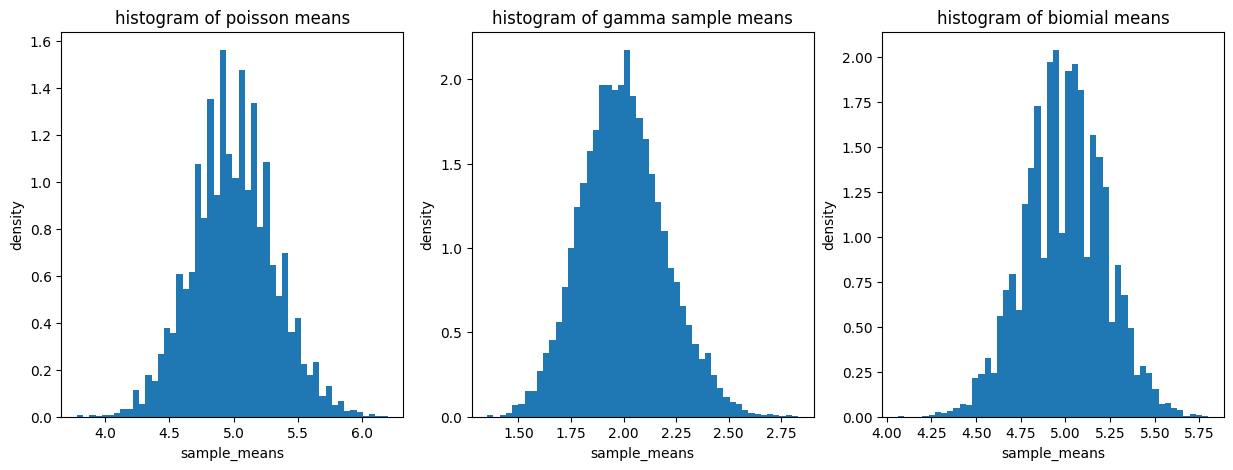

In [454]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [455]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 2.0030268586743447
Emperical variance: 0.07441116849132924


CASE STUDY

In [456]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [457]:
battery_csv.shape

(1200, 11)

In [458]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
682,3,8.986933,0,48499,785,54.721026,27.926206,67.273040,28.426466,40458.595306,81.787570
932,7,11.339168,0,62040,1500,63.693276,39.009847,76.982461,31.702103,46785.863333,75.396673
206,9,2.691621,0,53959,1500,32.750681,25.390181,51.542704,29.965170,37777.237085,70.162216
939,2,8.806385,0,65968,417,54.477018,37.115079,64.643526,29.756371,60471.958767,90.995079
319,4,8.803277,0,65307,1081,50.347317,35.758330,74.290257,31.583541,55672.267426,85.861170
...,...,...,...,...,...,...,...,...,...,...,...
440,9,10.634954,0,45179,1500,79.357536,54.133696,97.966604,34.834899,28303.128773,64.245741
76,5,7.592957,0,70368,1237,44.192222,33.328722,73.054988,28.254986,58199.349423,83.345284
915,3,10.091111,0,78927,754,69.730752,48.212687,84.192284,32.417014,70840.659066,87.624726
317,8,10.115799,0,57516,1500,63.138757,47.471194,60.995402,30.278774,40136.868762,69.547983


In [459]:
d['Daily Usage Hours'].mean()

np.float64(6.435078131250979)

<Axes: ylabel='Density'>

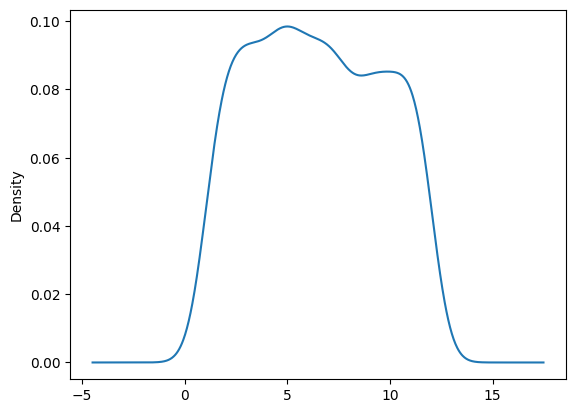

In [460]:
d['Daily Usage Hours'].plot(kind='density')

In [461]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
951,7.664865
704,3.173115
1176,8.110481
791,1.876866
921,6.163475
1190,2.600670
729,6.698115
312,3.081154
79,5.324618
91,9.606684


In [462]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[2.4661268389039046,
 6.215737404669876,
 4.773293838490268,
 2.454955866083299,
 9.015219126602627,
 10.82634943166935,
 11.3917811983973,
 4.159433301256659,
 7.331527715040902,
 4.656693613918017,
 4.956431173453746,
 6.857179986722871,
 4.386010650287311,
 2.796898947174721,
 3.5116437760547194,
 8.75544996988952,
 1.8000844255653523,
 4.471965369038675,
 10.340078219545436,
 9.917519273713513,
 4.438578273991301,
 5.267700298376751,
 4.76033946108984,
 11.810134950014245,
 2.845960552106315,
 11.001223498271358,
 3.657614040793393,
 10.492555856443204,
 5.060498131901249,
 6.038314782422555,
 3.874663196739221,
 3.496763934186731,
 3.8339519863988207,
 11.484321258335516,
 8.6080774217065,
 11.528483157937757,
 2.5339525982567617,
 5.816898758572036,
 6.308613592276728,
 3.3206687968194544,
 11.0650169152228,
 9.555007010745724,
 2.857443097074345,
 8.622122521472674,
 6.866559026455655,
 5.217368551640848,
 4.653897742679058,
 10.95828898911567,
 1.42240965058979,
 4.170029785554

In [463]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [464]:
samples

[[3.775462097486683,
  9.745126906213176,
  6.888825448678224,
  9.801513410272834,
  10.871370501537449,
  1.897324181725025,
  11.54759060509451,
  5.939863655483634,
  6.3184789361748415,
  10.603474617167237,
  4.76850191092245,
  2.0636401576632384,
  1.8443386807761184,
  10.770104846274345,
  1.66996097558701,
  9.335542164126736,
  3.274996824467359,
  7.279393299066378,
  6.597834770768682,
  3.50229764062894,
  5.610094202087938,
  11.005549302220388,
  7.034472565601574,
  10.67727642523778,
  11.442004168701786,
  4.776030379708931,
  4.6317154534716485,
  4.689087668392087,
  2.1728598083025767,
  11.18665515800092,
  3.4064887925196765,
  10.400021325223983,
  9.36440074016231,
  11.9867222939722,
  6.103839591844189,
  1.2981731756985642,
  6.308613592276728,
  4.75805223959662,
  8.100877920515746,
  10.877507378035212,
  11.216887567566738,
  2.820497521300212,
  3.7497017995571262,
  10.333189518468911,
  6.99010857120143,
  1.70504182139793,
  11.066082999390328,
  6

In [465]:
samples=np.array(samples)
samples

array([[ 3.7754621 ,  9.74512691,  6.88882545, ...,  6.62203204,
        11.94963664, 11.6340765 ],
       [11.22343832,  7.27997759, 10.22739248, ...,  1.60071334,
         7.37244743,  1.27719004],
       [ 6.40121739,  3.7754621 ,  6.24681732, ...,  5.68056225,
         5.89337676,  2.35612157],
       ...,
       [ 1.26405549,  3.39198225,  8.90589925, ...,  8.87583163,
        10.61738068,  7.10155727],
       [ 7.8553141 ,  3.62626948,  4.11042003, ...,  1.54143006,
         6.55402596,  3.3206688 ],
       [ 7.70650099, 11.31870554, 10.11579882, ..., 11.8610532 ,
         7.60871364,  4.95643117]])

In [466]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [467]:
sampling_means.mean()

np.float64(6.5015410094092285)

In [468]:
sampling_means.std()/np.sqrt(50)

np.float64(0.059602740166880296)

<Axes: ylabel='Density'>

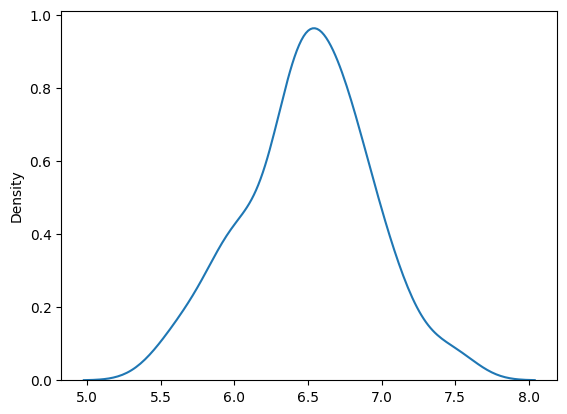

In [469]:
sns.kdeplot(data=sampling_means)

In [470]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.382335529075468 - 6.620746489742989


t-test

In [471]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [472]:
train=df.drop(columns=['Battery Health'])
test=df['Battery Health']

In [473]:
final=pd.concat([train,test]).sample(1000)

In [474]:
corr = df.corr(numeric_only=True)['Battery Health'].drop(
    'Battery Health'
)
print(corr)

Battery Age            -0.900723
Daily Usage Hours      -0.084347
Gaming User             0.018509
Design Capacity         0.289450
Cycle Count            -0.921454
CPU Usage              -0.052363
GPU Usage              -0.033122
Power Consumption      -0.048988
Average Temperature    -0.041134
Full Charge Capacity    0.704030
Name: Battery Health, dtype: float64


In [475]:
meanf=np.mean(df['Full Charge Capacity'])
print(meanf)

51798.12594357623


In [476]:
#H_0:u=51798.13
#H_a:u!=51798.13

In [477]:
vals=final['Full Charge Capacity'].dropna()

In [478]:
sample_vals=vals.sample(200).values
sample_vals

array([53953.4217759 , 50407.43883308, 36010.88938638, 53247.09491242,
       48460.03051248, 44474.428363  , 39936.07851021, 59870.27040333,
       57561.        , 51219.65029176, 57646.33093843, 45421.45717417,
       37432.43992639, 34392.94928028, 46882.99785375, 43090.78133902,
       51950.41274877, 61074.40515352, 40822.76009464, 47719.05833457,
       45465.67064796, 59165.45338447, 60864.63403546, 37129.77747999,
       43709.2360448 , 54035.61407232, 62263.92844488, 57266.25847668,
       56010.25870899, 61891.59415027, 30982.85978856, 53305.92779465,
       57510.75130111, 47736.23197368, 46988.68469475, 35433.94455488,
       46508.43104036, 65140.        , 69737.59611919, 54866.29851776,
       48414.        , 47158.48070436, 54360.15736121, 52773.44034463,
       60001.66934949, 54304.58227662, 57782.89648361, 44651.81461827,
       47638.27343862, 53310.69603264, 41747.67721121, 45044.13436264,
       63528.85410346, 73841.09265617, 40764.88760732, 68759.78459188,
      

In [479]:
mean_s=np.mean(sample_vals)
print(mean_s)
std_s=np.std(sample_vals)
print(std_s)

51271.73232698118
11730.403328927041


In [480]:
#check normality using shapiro wilk test
from scipy.stats import shapiro

shapiro_s=shapiro(sample_vals)
print(shapiro_s)

ShapiroResult(statistic=np.float64(0.979526269246991), pvalue=np.float64(0.005098397874162889))


In [481]:
import scipy.stats as stats

t_statistics,p_value=stats.ttest_1samp(sample_vals,50000)
print(t_statistics,p_value/2)


1.5293585114238866 0.06388179592572031


INDEPENDENT 2SAMPLE T-TEST

In [482]:
url="https://raw.githubusercontent.com/SUCCESSneeded/practice/refs/heads/main/E%20Commerce%20Dataset%20(1).csv?token=GHSAT0AAAAAAEMA73SSG6GXW34AKAJOXY3W2W3JKPA"
df2=pd.read_csv(url)
print(df2.head())
df2.shape

   CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0       50001      1     4.0         Mobile Phone         3              6.0   
1       50002      1     NaN                Phone         1              8.0   
2       50003      1     NaN                Phone         1             30.0   
3       50004      1     0.0                Phone         3             15.0   
4       50005      1     0.0                Phone         1             12.0   

  PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0           Debit Card  Female             3.0                         3   
1                  UPI    Male             3.0                         4   
2           Debit Card    Male             2.0                         4   
3           Debit Card    Male             2.0                         4   
4                   CC    Male             NaN                         3   

     PreferedOrderCat  SatisfactionScore MaritalStatus  Number

(5630, 20)

In [483]:
churn=df2.dropna()
print(churn.head())
churn.shape

    CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0        50001      1     4.0         Mobile Phone         3              6.0   
3        50004      1     0.0                Phone         3             15.0   
5        50006      1     0.0             Computer         1             22.0   
11       50012      1    11.0         Mobile Phone         1              6.0   
12       50013      1     0.0                Phone         1             11.0   

   PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0            Debit Card  Female             3.0                         3   
3            Debit Card    Male             2.0                         4   
5            Debit Card  Female             3.0                         5   
11           Debit Card    Male             3.0                         4   
12                  COD    Male             2.0                         3   

      PreferedOrderCat  SatisfactionScore MaritalS

(3774, 20)

In [484]:
churn.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
5,50006,1,0.0,Computer,1,22.0,Debit Card,Female,3.0,5,Mobile Phone,5,Single,2,1,22.0,4.0,6.0,7.0,139
11,50012,1,11.0,Mobile Phone,1,6.0,Debit Card,Male,3.0,4,Fashion,3,Single,10,1,13.0,0.0,1.0,0.0,154
12,50013,1,0.0,Phone,1,11.0,COD,Male,2.0,3,Mobile,3,Single,2,1,13.0,2.0,2.0,2.0,134


In [485]:
corr = df2.corr(numeric_only=True)['CashbackAmount'].drop(
    'CashbackAmount'
)
print(corr)

CustomerID                     0.217173
Churn                         -0.154161
Tenure                         0.476577
CityTier                       0.055698
WarehouseToHome               -0.009536
HourSpendOnApp                 0.121469
NumberOfDeviceRegistered       0.137396
SatisfactionScore              0.003429
NumberOfAddress                0.186802
Complain                       0.000598
OrderAmountHikeFromlastYear    0.017961
CouponUsed                     0.286391
OrderCount                     0.360527
DaySinceLastOrder              0.346777
Name: CashbackAmount, dtype: float64


In [486]:
mobile_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Phone", case=False, na=False
    )
].copy()

# Dataset for computers and laptops
computer_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Laptop|Computer", case=False, na=False, regex=True
    )
].copy()

print("Mobile dataset:", mobile_df.shape)
print("Computer dataset:", computer_df.shape)
print(mobile_df)

Mobile dataset: (1227, 20)
Computer dataset: (1961, 20)
      CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  \
5          50006      1     0.0             Computer         1   
19         50020      1    19.0         Mobile Phone         1   
25         50026      1     0.0                Phone         1   
50         50051      0    29.0                Phone         1   
52         50053      1     0.0         Mobile Phone         1   
...          ...    ...     ...                  ...       ...   
5615       55616      0    14.0         Mobile Phone         1   
5617       55618      0    14.0                Phone         1   
5618       55619      0     9.0         Mobile Phone         1   
5620       55621      0     3.0         Mobile Phone         1   
5624       55625      0     1.0         Mobile Phone         3   

      WarehouseToHome PreferredPaymentMode  Gender  HourSpendOnApp  \
5                22.0           Debit Card  Female             3.0   
19         

In [487]:
mobile_sample=mobile_df.sample(100)
computer_sample=computer_df.sample(100)

print(mobile_sample.shape)
print(computer_sample.shape)

(100, 20)
(100, 20)


(array([ 1.,  0.,  0.,  2., 10., 36., 28., 12.,  5.,  6.]),
 array([111. , 117.4, 123.8, 130.2, 136.6, 143. , 149.4, 155.8, 162.2,
        168.6, 175. ]),
 <BarContainer object of 10 artists>)

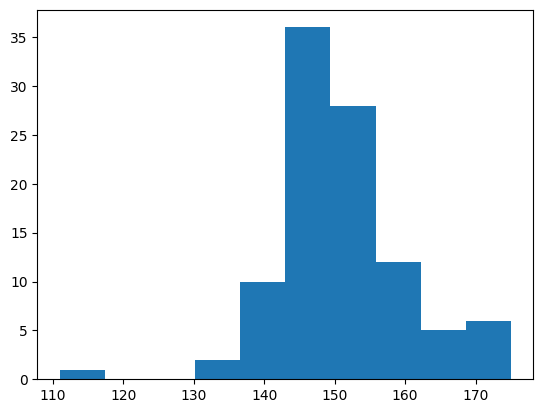

In [488]:
plt.hist(mobile_sample['CashbackAmount'])

In [489]:
mobile_smean=np.mean(mobile_sample['CashbackAmount'])
mobile_sstd=np.std(mobile_sample['SatisfactionScore'])

computer_smean=np.mean(computer_sample['CashbackAmount'])
computer_sstd=np.std(computer_sample['CashbackAmount'])
print(mobile_smean,mobile_sstd)
print(computer_smean,computer_sstd)

151.14 1.4945233353815528
162.28 20.998133250362987


In [490]:
from sklearn.preprocessing import PowerTransformer
from scipy.stats import shapiro

# Create transformer
pt = PowerTransformer(method='yeo-johnson', standardize=True)
# Transform mobile sample
mobile_sample['CashbackAmount_normal'] = pt.fit_transform(
    mobile_sample[['CashbackAmount']]
)

# Transform computer sample using its own fitted transformer
pt2 = PowerTransformer(method='yeo-johnson', standardize=True)

computer_sample['CashbackAmount_normal'] = pt2.fit_transform(
    computer_sample[['CashbackAmount']]
)

print("Mobile:", shapiro(mobile_sample['CashbackAmount_normal']))
print("Computer:", shapiro(computer_sample['CashbackAmount_normal']))

Mobile: ShapiroResult(statistic=np.float64(0.9351446732101867), pvalue=np.float64(9.867664313045452e-05))
Computer: ShapiroResult(statistic=np.float64(0.9600137192316351), pvalue=np.float64(0.00403024554688697))


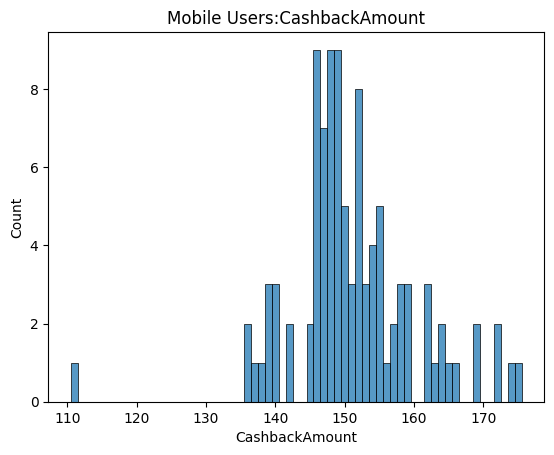

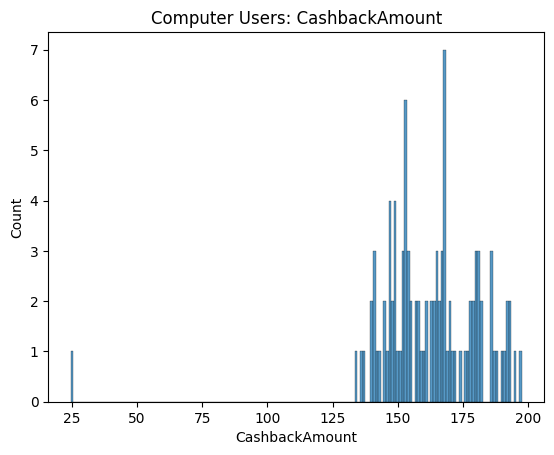

In [491]:
sns.histplot(mobile_sample["CashbackAmount"], discrete=True)
plt.title("Mobile Users:CashbackAmount")
plt.show()

sns.histplot(computer_sample["CashbackAmount"], discrete=True)
plt.title("Computer Users: CashbackAmount")
plt.show()

In [492]:
from scipy.stats import levene

l_test=levene(mobile_sample['CashbackAmount'],computer_sample['CashbackAmount'])
print(l_test)
'''pvalue > 0.05 therefor popvarP==popvarC'''

LeveneResult(statistic=np.float64(24.852157323809312), pvalue=np.float64(1.3480759354593721e-06))


'pvalue > 0.05 therefor popvarP==popvarC'

In [493]:
from scipy.stats import t
t_val=6.31
dof=198
cdf_val=t.cdf(t_val,dof)
print(cdf_val*2)

1.9999999982097374
